In [38]:
import numpy as np
from pydmd import HankelDMD, DMD, BOPDMD
import matplotlib.pylab as plt
from tqdm.auto import tqdm
plt.rcParams['figure.dpi']=400
np.set_printoptions(suppress=True,precision=6,linewidth=100000) # Improve print statements

RSE = lambda X,Y,Y_train: np.sum((Y-np.real(X))**2)/np.sum((Y_train-np.mean(Y_train))**2)
RSE2 = lambda X,Y,Y_train: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y_train))**2)
RAE = lambda X,Y,Y_train: np.sum(np.abs(Y-np.real(X)))/np.sum(np.abs(Y-np.mean(Y_train)))
# Model reconstruction = X, true data = Y

def MASE(yhat,y,y_train):
    # Model reconstruction = yhat, true data = Y, train data = y_train
    yhat_error = np.mean(np.abs(y-yhat))
    naive_error = np.mean(np.abs(y_train[:1]-y_train[:-1]))
    return yhat_error / naive_error

SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy')[:5000,:50].T
SV_normalized = SV[:50,:2000]/np.linalg.norm(SV[:50,:2000])

def dynamics(dmd,timesteps,t0,dt):
    temp = np.repeat(dmd.eigs[:, None], timesteps.shape[0], axis=1)
    tpow = (timesteps - t0) / dt
    return np.power(temp, tpow) * dmd.amplitudes[:, None]

def dynamics_hopt(dmd,timesteps,t0,dt):
        temp = np.repeat(np.exp(dmd.eigs)[:, None], timesteps.shape[0], axis=1)
        tpow = (timesteps - t0) / dt
        return np.power(temp, tpow) * dmd.amplitudes[:, None]

# Reconstructing Data

I have demonstrated that given the model $H=\Phi B\Omega$ for the data in the Hankel matrix space, where $H$ consists of stacked Hankel matrices, and given that we are using the 'first' reconstruction method, for $j\geq d$ the model in the observed space is of the form

$$x_j=\sum_{k=1}^r b_k \psi_k e^{\lambda_k t_j}$$

where $\psi_{i,j}=\phi_{di,j}e^{-\lambda_jt_{d-1}}$ (see overleaf document). There is a slight change in indexing with pydmd as pydmd stacks the Hankel matrices so that the first $n$ rows of $H$ correspond to the first rows of the $n$ Hankel matrices, the second $n$ rows of $H$ correspond to the second rows of the $n$ Hankel matrices, and so on. The above formula says that $\psi_i$ is the the last row of $\Phi$ corresponding to the $i$th Hankel matrix multiplied by a constant. So with this new permutation of indices, we now have $\psi_{i,j}=\phi_{nd-d+i,j}e^{-\lambda_jt_{d-1}}.$ Keep in mind that this formula is valid for $j\geq d$ only. I will demonstrate that this actually works below.

/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning: Input data condition number 1230311.875. Consider preprocessing data, passing in augmented data
matrix, or regularization methods.
  warnings.warn(
/home/msw1/.local/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1369: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


[]

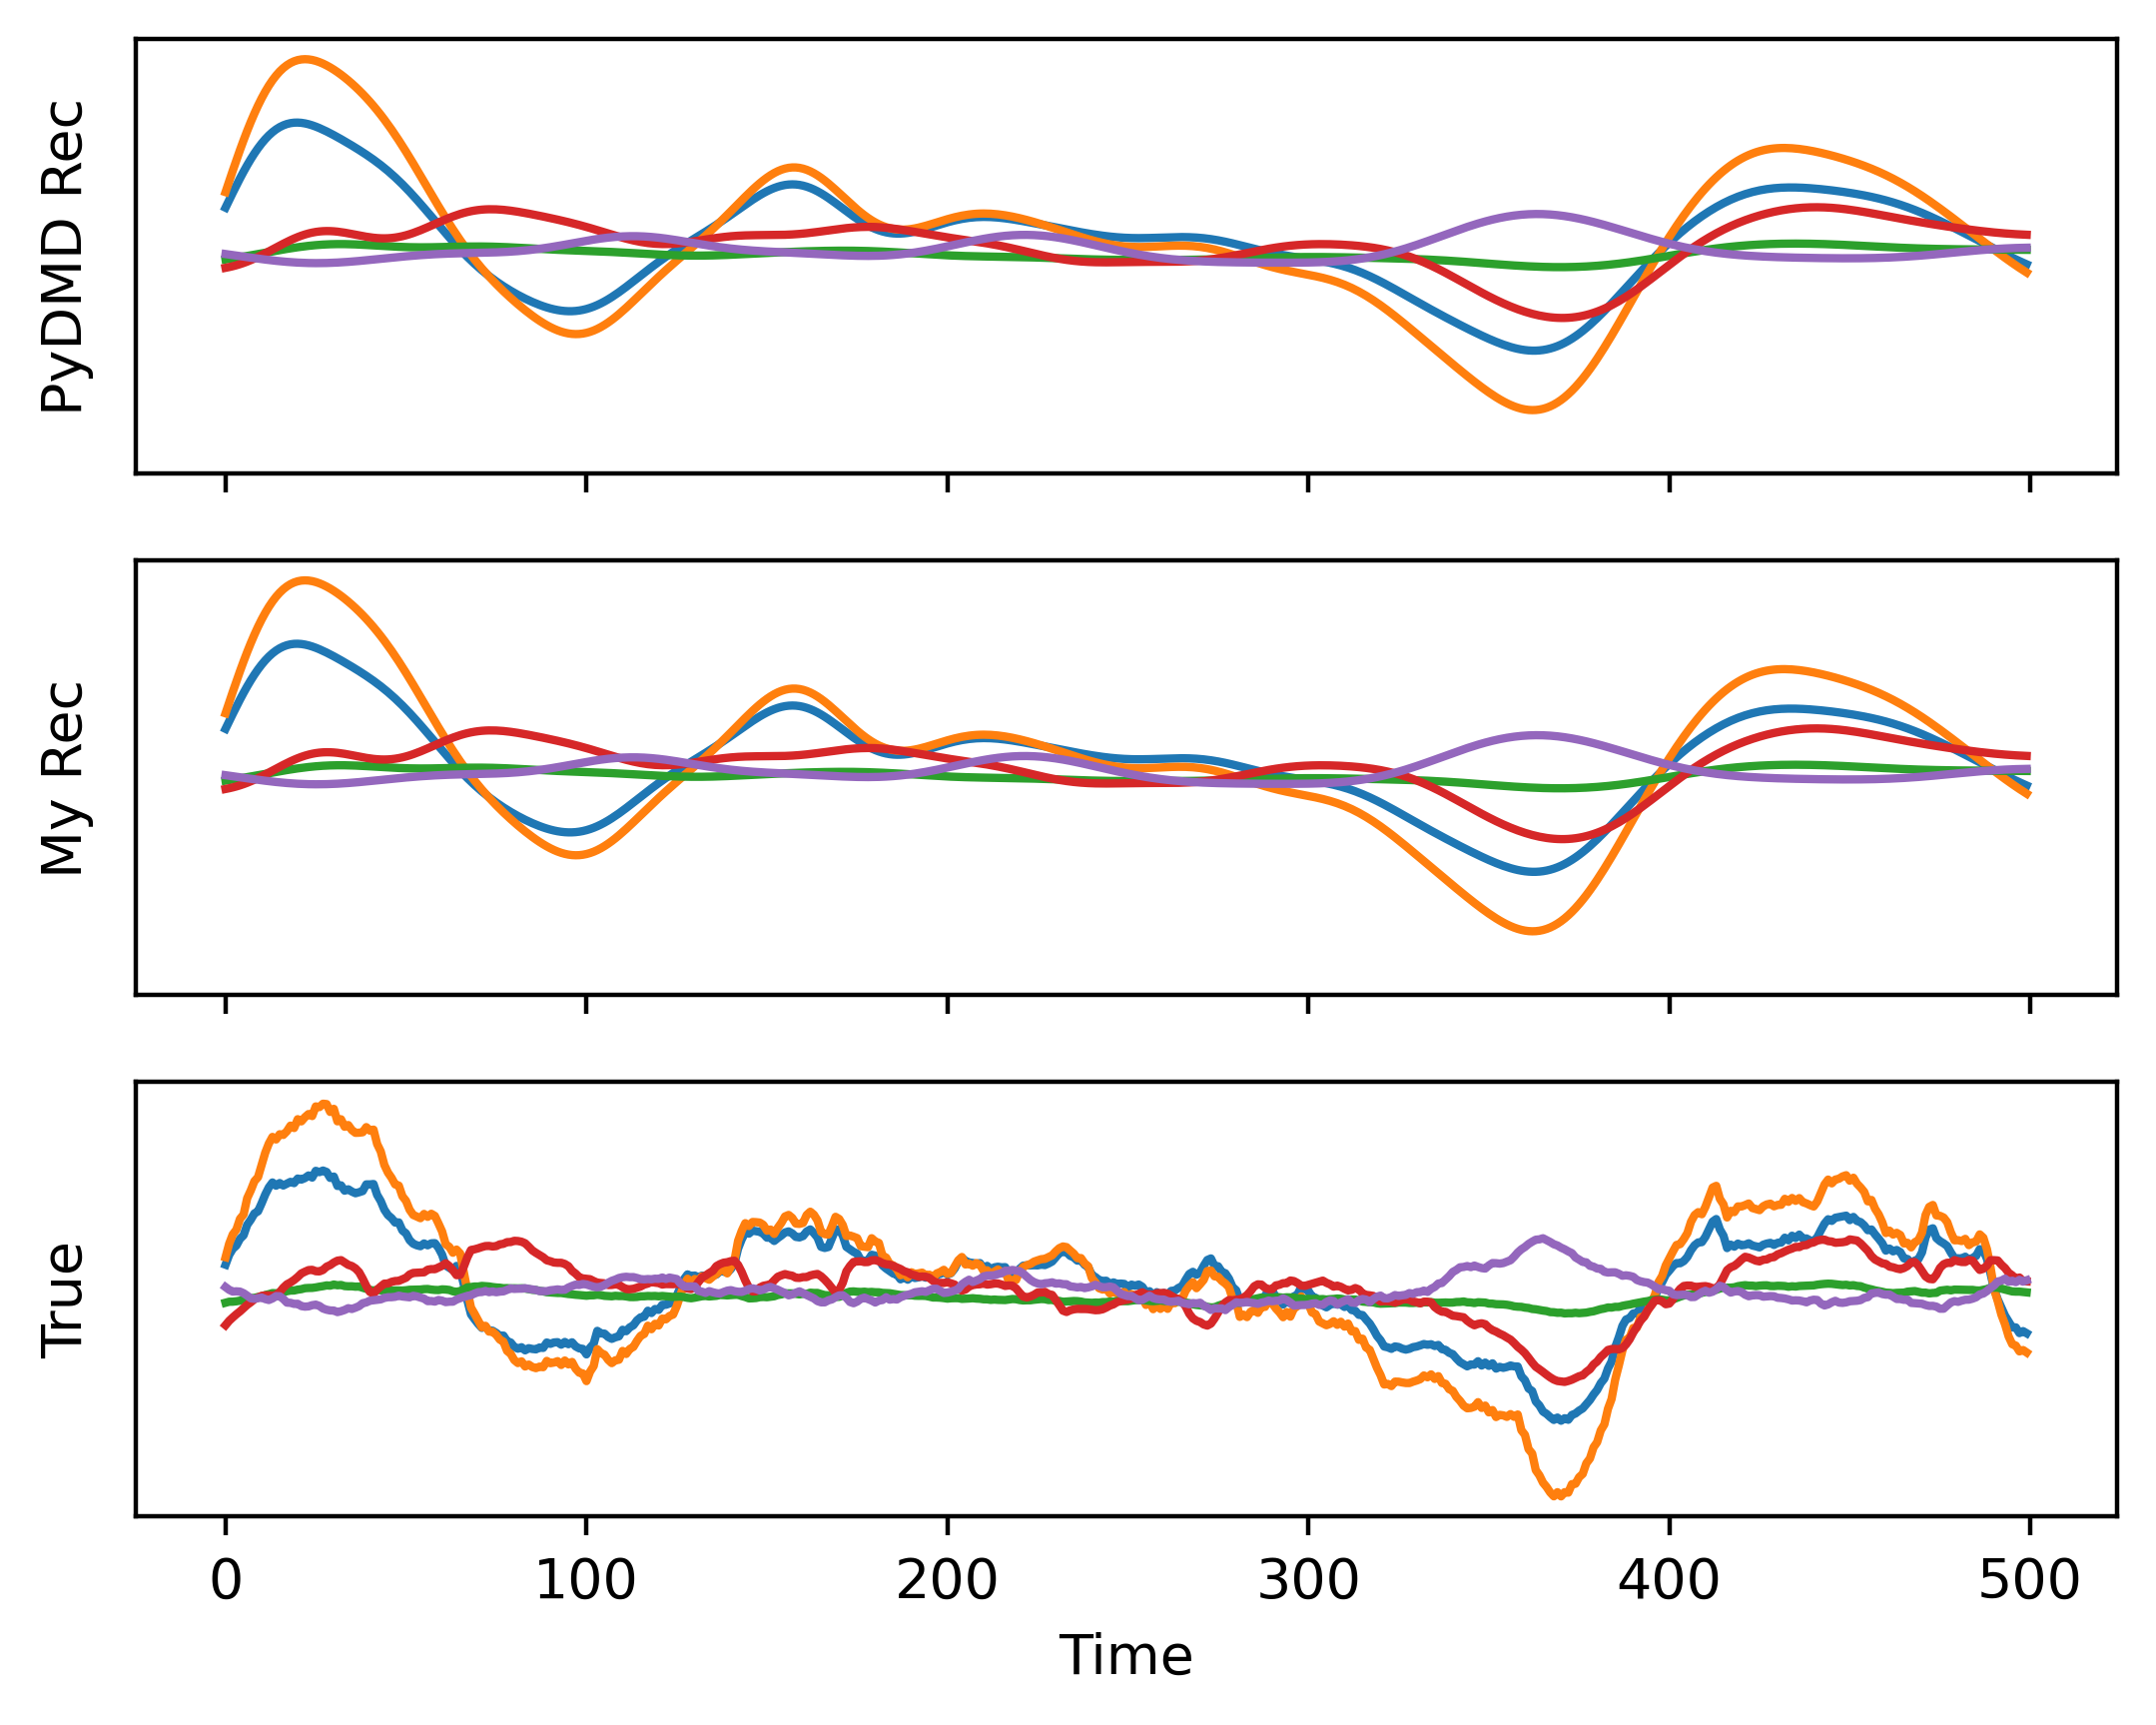

In [2]:
hdmd = HankelDMD(svd_rank=24,d=500,reconstruction_method='first',opt=True,tikhonov_regularization=1e-4)
hdmd.fit(SV_normalized[:,:1000])
pydmd_reconstruction = hdmd.reconstructed_data[:,500:]
psi = hdmd.modes[-50:,:]*np.exp(-np.log(hdmd.eigs)*(hdmd.d-1))
my_reconstruction = psi@hdmd.dynamics[:,500:]

fig,ax = plt.subplots(3,sharex=True,sharey=True)
ax[0].plot(pydmd_reconstruction[:5,:].T)
ax[0].set_ylabel("PyDMD Rec")
ax[1].plot(my_reconstruction[:5,:].T)
ax[1].set_ylabel("My Rec")
ax[2].plot(SV_normalized[:5,500:1000].T)
ax[2].set_ylabel("True")
ax[2].set_xlabel("Time")
ax[0].set_yticks([])

So we can see that the pydmd reconstruction and my reconstruction formulation are identical. Thus, the math is correct; the reconstruction can be written in the above form that we would like it to be in.

# Orthogonality, normality, conditioning, and pseudospectra of DMD Operators

Another interesting thing is that the low-rank operator has a very clear structure.

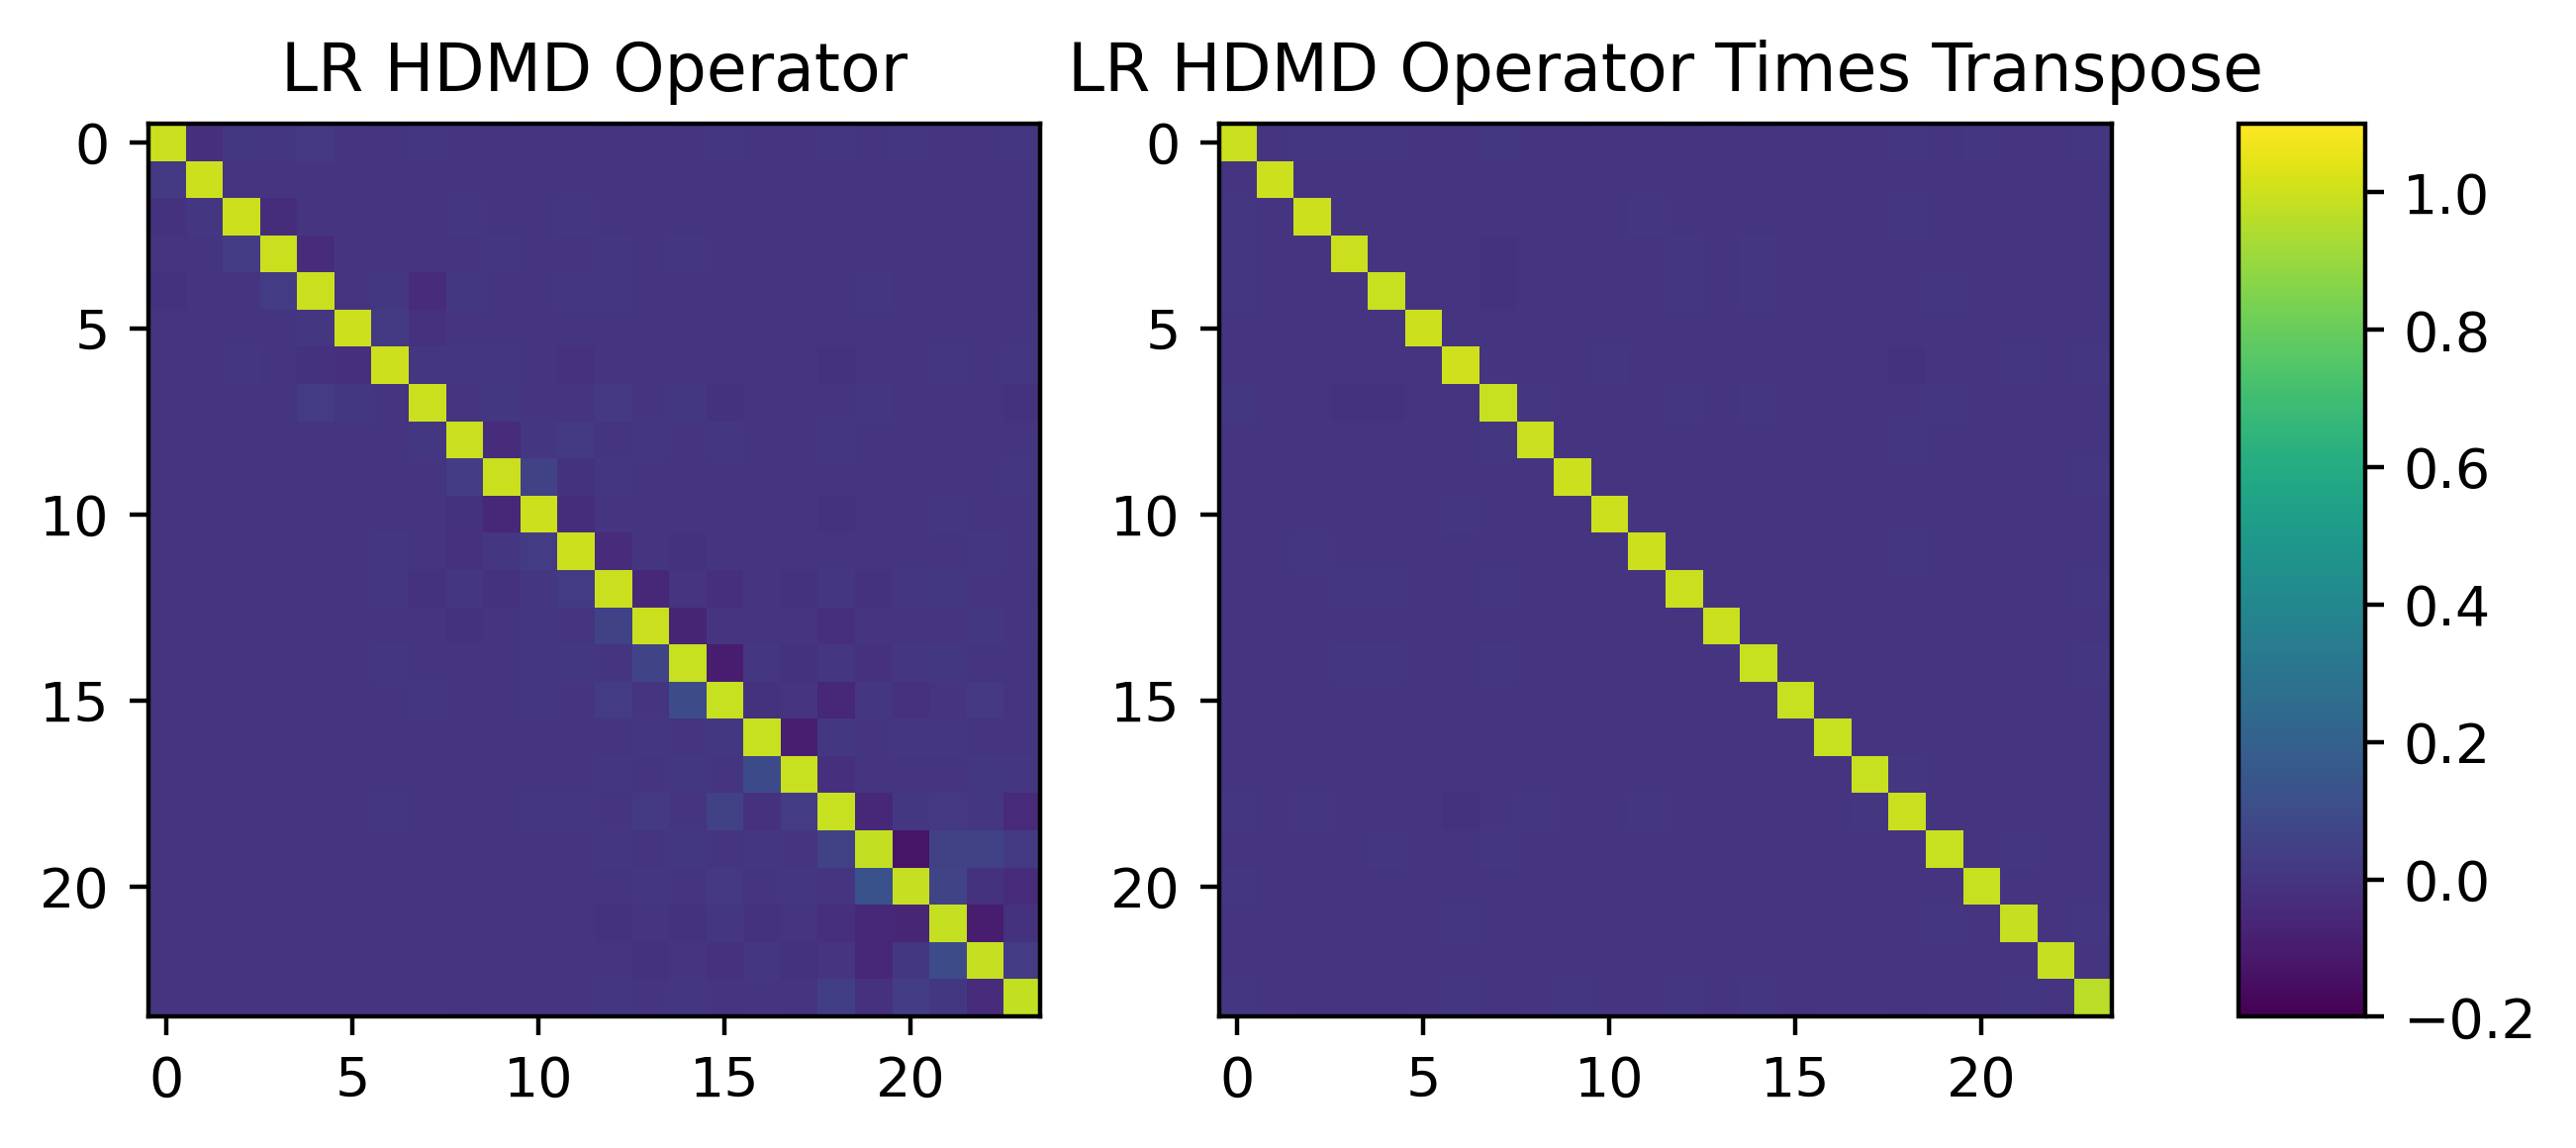

In [3]:
hankel_A = hdmd._sub_dmd._Atilde.as_numpy_array
fig,ax = plt.subplots(1,2)
ax[0].imshow(hankel_A,vmin=-0.2,vmax=1.1)
ax[0].set_title("LR HDMD Operator")
last_ax = ax[1].imshow(hankel_A@hankel_A.T,vmin=-0.2,vmax=1.1)
ax[1].set_title("LR HDMD Operator Times Transpose")
cbar_ax = fig.add_axes([0.95, 0.26, 0.05, 0.47])
fig.colorbar(last_ax, cax=cbar_ax)

Not only is this matrix nearly diagonal, it is nearly orthogonal.

Let's fit exact DMD and OptDMD to the same data.

In [4]:
from pydmd import BOPDMD
dmd = HankelDMD(svd_rank=24,opt=True,tikhonov_regularization=1e-4)
dmd.fit(SV_normalized[:,:1000])
optdmd = BOPDMD(svd_rank=24,compute_A=True,use_proj=True)#eig_constraints=set({'stable'}))
optdmd.fit(SV_normalized[:,:1000],np.arange(1000))

DMD's low rank operator has a similar structure, though notably the diagonal entries decay, which is not seen in HankelDMD.

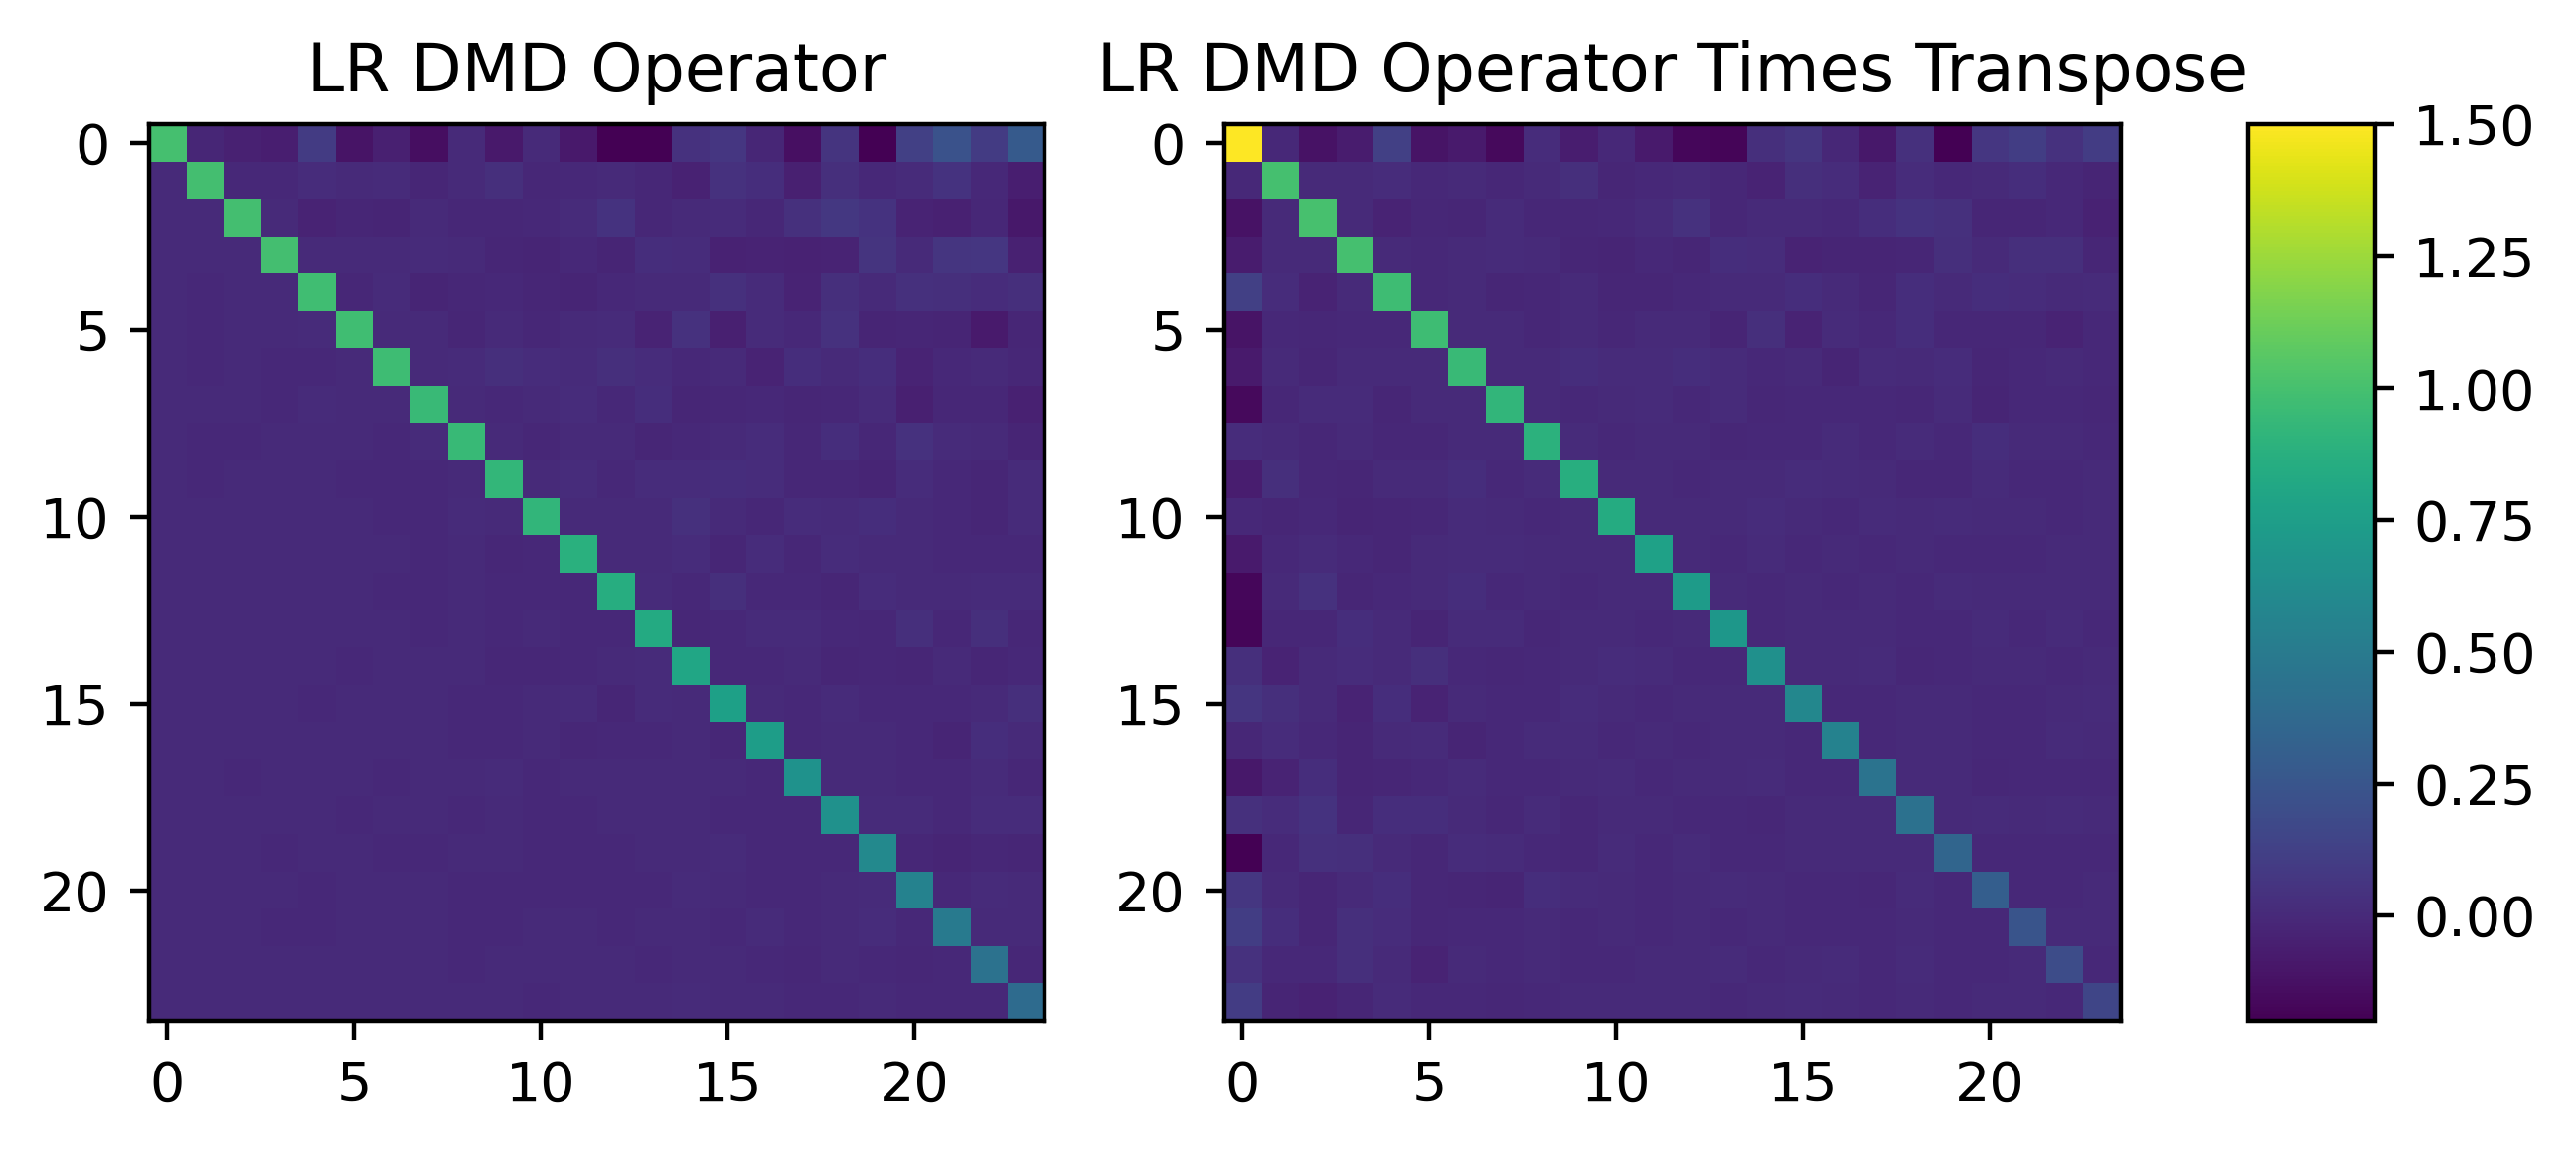

In [5]:
#plt.title("Low Rank DMD Operator")
fig,ax = plt.subplots(1,2)
dmd_A = dmd.operator.as_numpy_array
ax[0].imshow(dmd_A,vmin=-0.2,vmax=1.5)
ax[0].set_title("LR DMD Operator")
last_ax = ax[1].imshow(dmd_A@dmd_A.T,vmin=-0.2,vmax=1.5)
ax[1].set_title("LR DMD Operator Times Transpose")
cbar_ax = fig.add_axes([0.95, 0.26, 0.05, 0.47])
fig.colorbar(last_ax, cax=cbar_ax)

Something similar occurs with OptDMD.

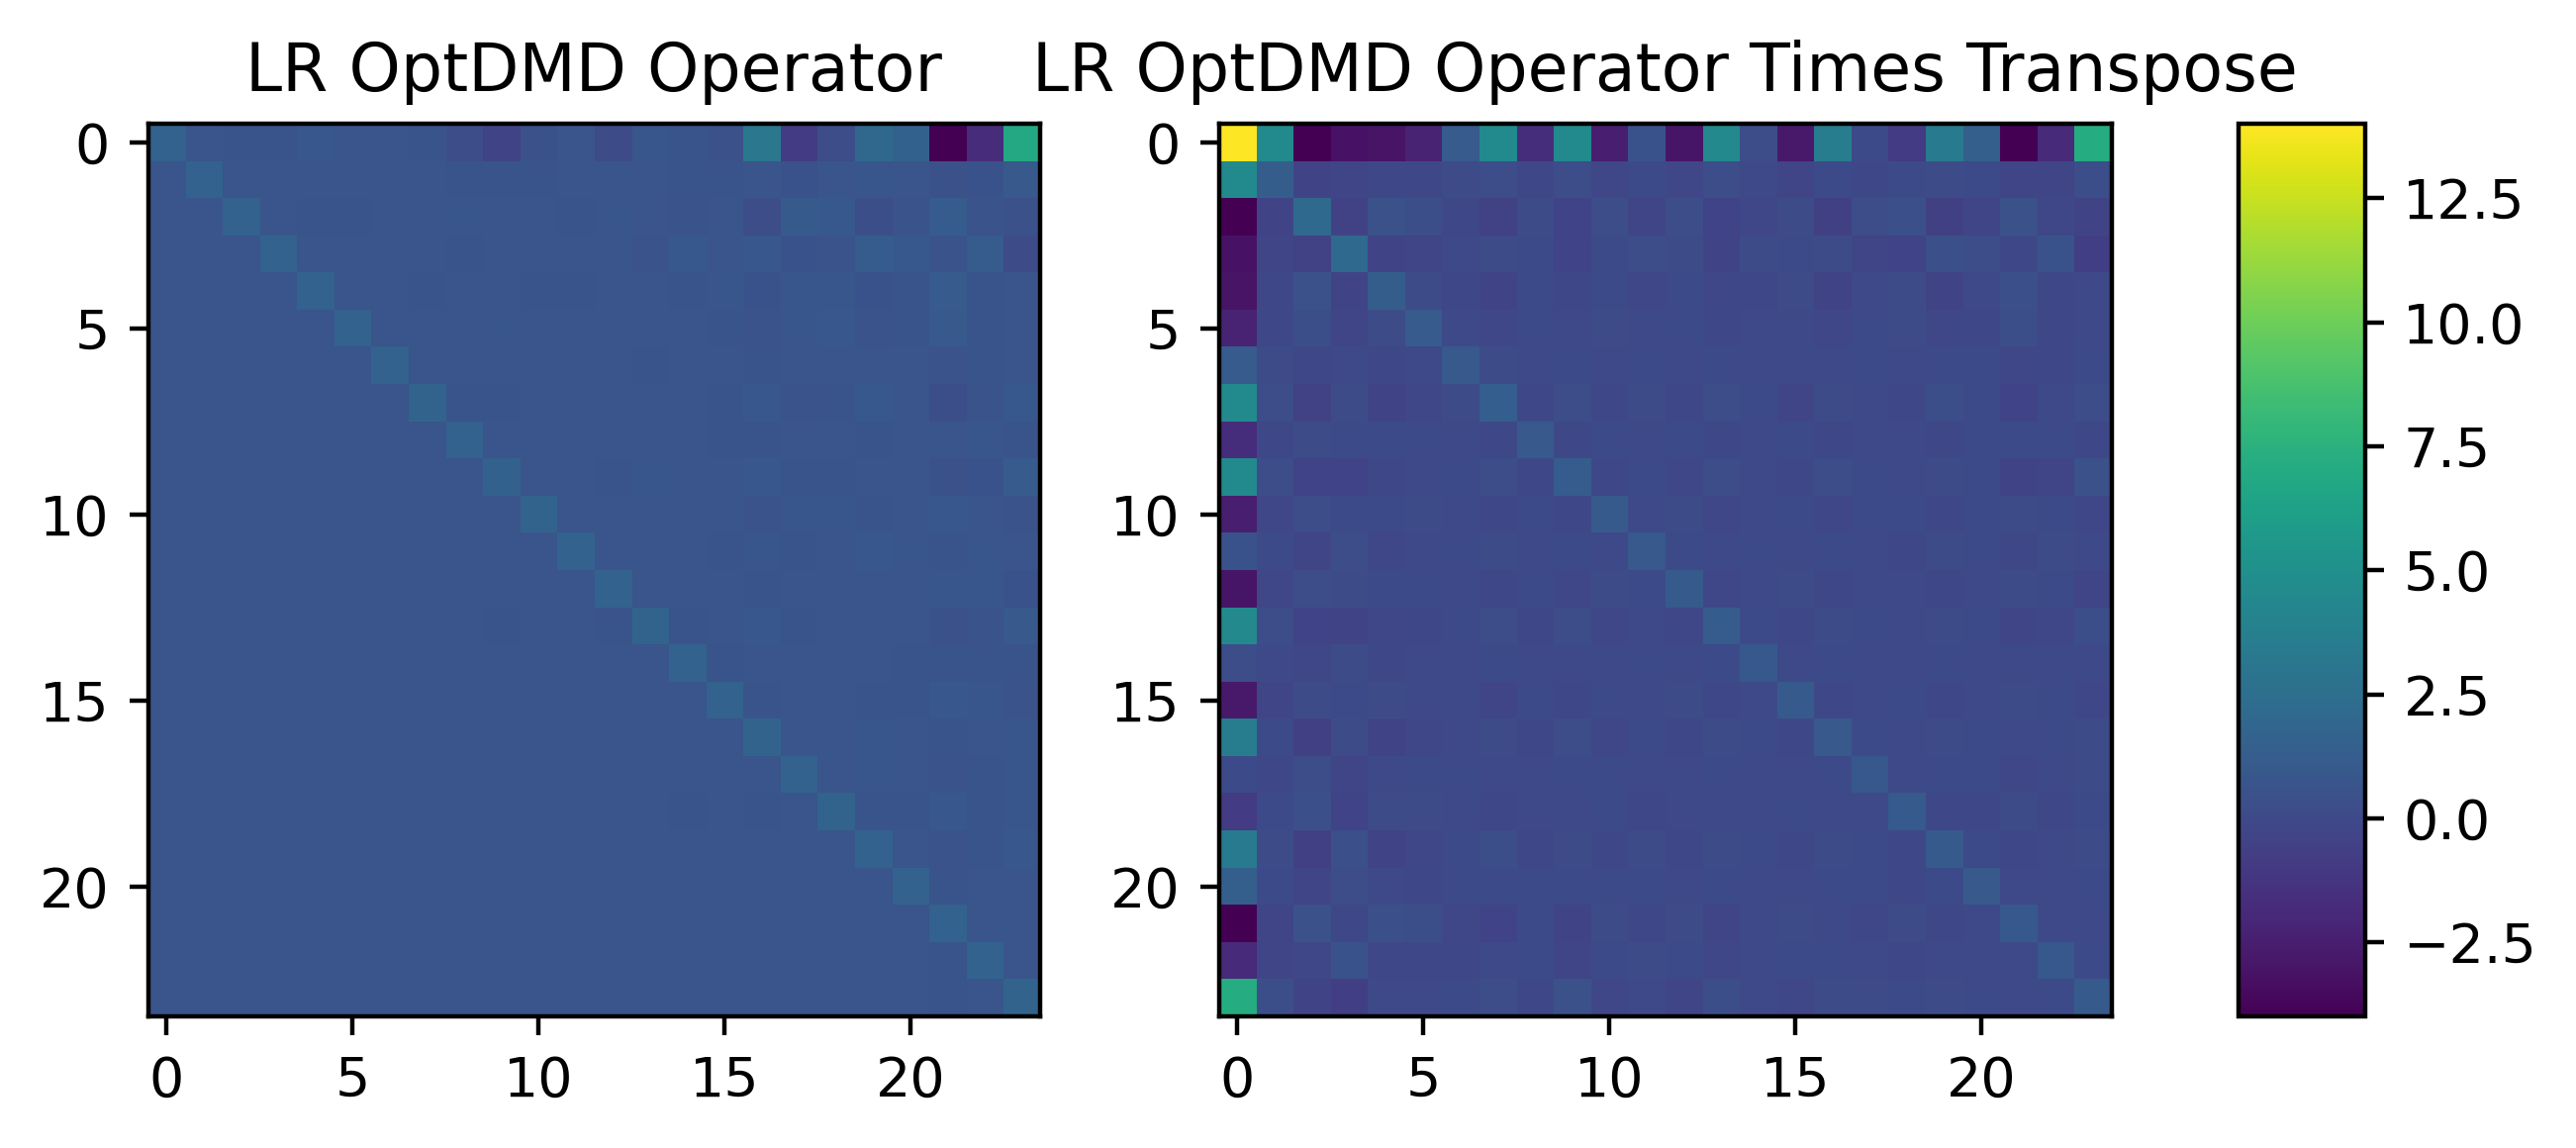

In [6]:
optdmd_left_proj = optdmd._proj_basis.conjugate().T@optdmd.modes
optdmd_right_proj = np.linalg.pinv(optdmd.modes)@optdmd._proj_basis
optdmd_A = optdmd_left_proj@np.diag(np.exp(optdmd.eigs))@optdmd_right_proj
fig,ax = plt.subplots(1,2)
ax[0].imshow(np.real(optdmd_A),vmin=-5,vmax=14)
ax[0].set_title("LR OptDMD Operator")
last_ax = ax[1].imshow(np.real(optdmd_A@optdmd_A.conjugate().T),vmin=-4,vmax=14)
ax[1].set_title("LR OptDMD Operator Times Transpose")
cbar_ax = fig.add_axes([0.95, 0.26, 0.05, 0.47])
fig.colorbar(last_ax, cax=cbar_ax)

#plt.title("Low Rank OptDMD Operator")
#plt.imshow(np.real(optdmd_A))

Next let's look at OptDMD fit to a Hankel matrix version of the data (Warning: computing the low rank A here is very expensive).

In [7]:
hankel = hdmd._pseudo_hankel_matrix(SV_normalized[:,:1000])
hoptdmd = BOPDMD(svd_rank=24,compute_A=True,use_proj=True)#,eig_constraints=set({'stable'}))
hoptdmd.fit(hankel,np.arange(501))
hoptdmd_left_proj = hoptdmd._proj_basis.conjugate().T@hoptdmd.modes
hoptdmd_right_proj = np.linalg.pinv(hoptdmd.modes)@hoptdmd._proj_basis
hoptdmd_A = hoptdmd_left_proj@np.diag(np.exp(hoptdmd.eigs))@hoptdmd_right_proj

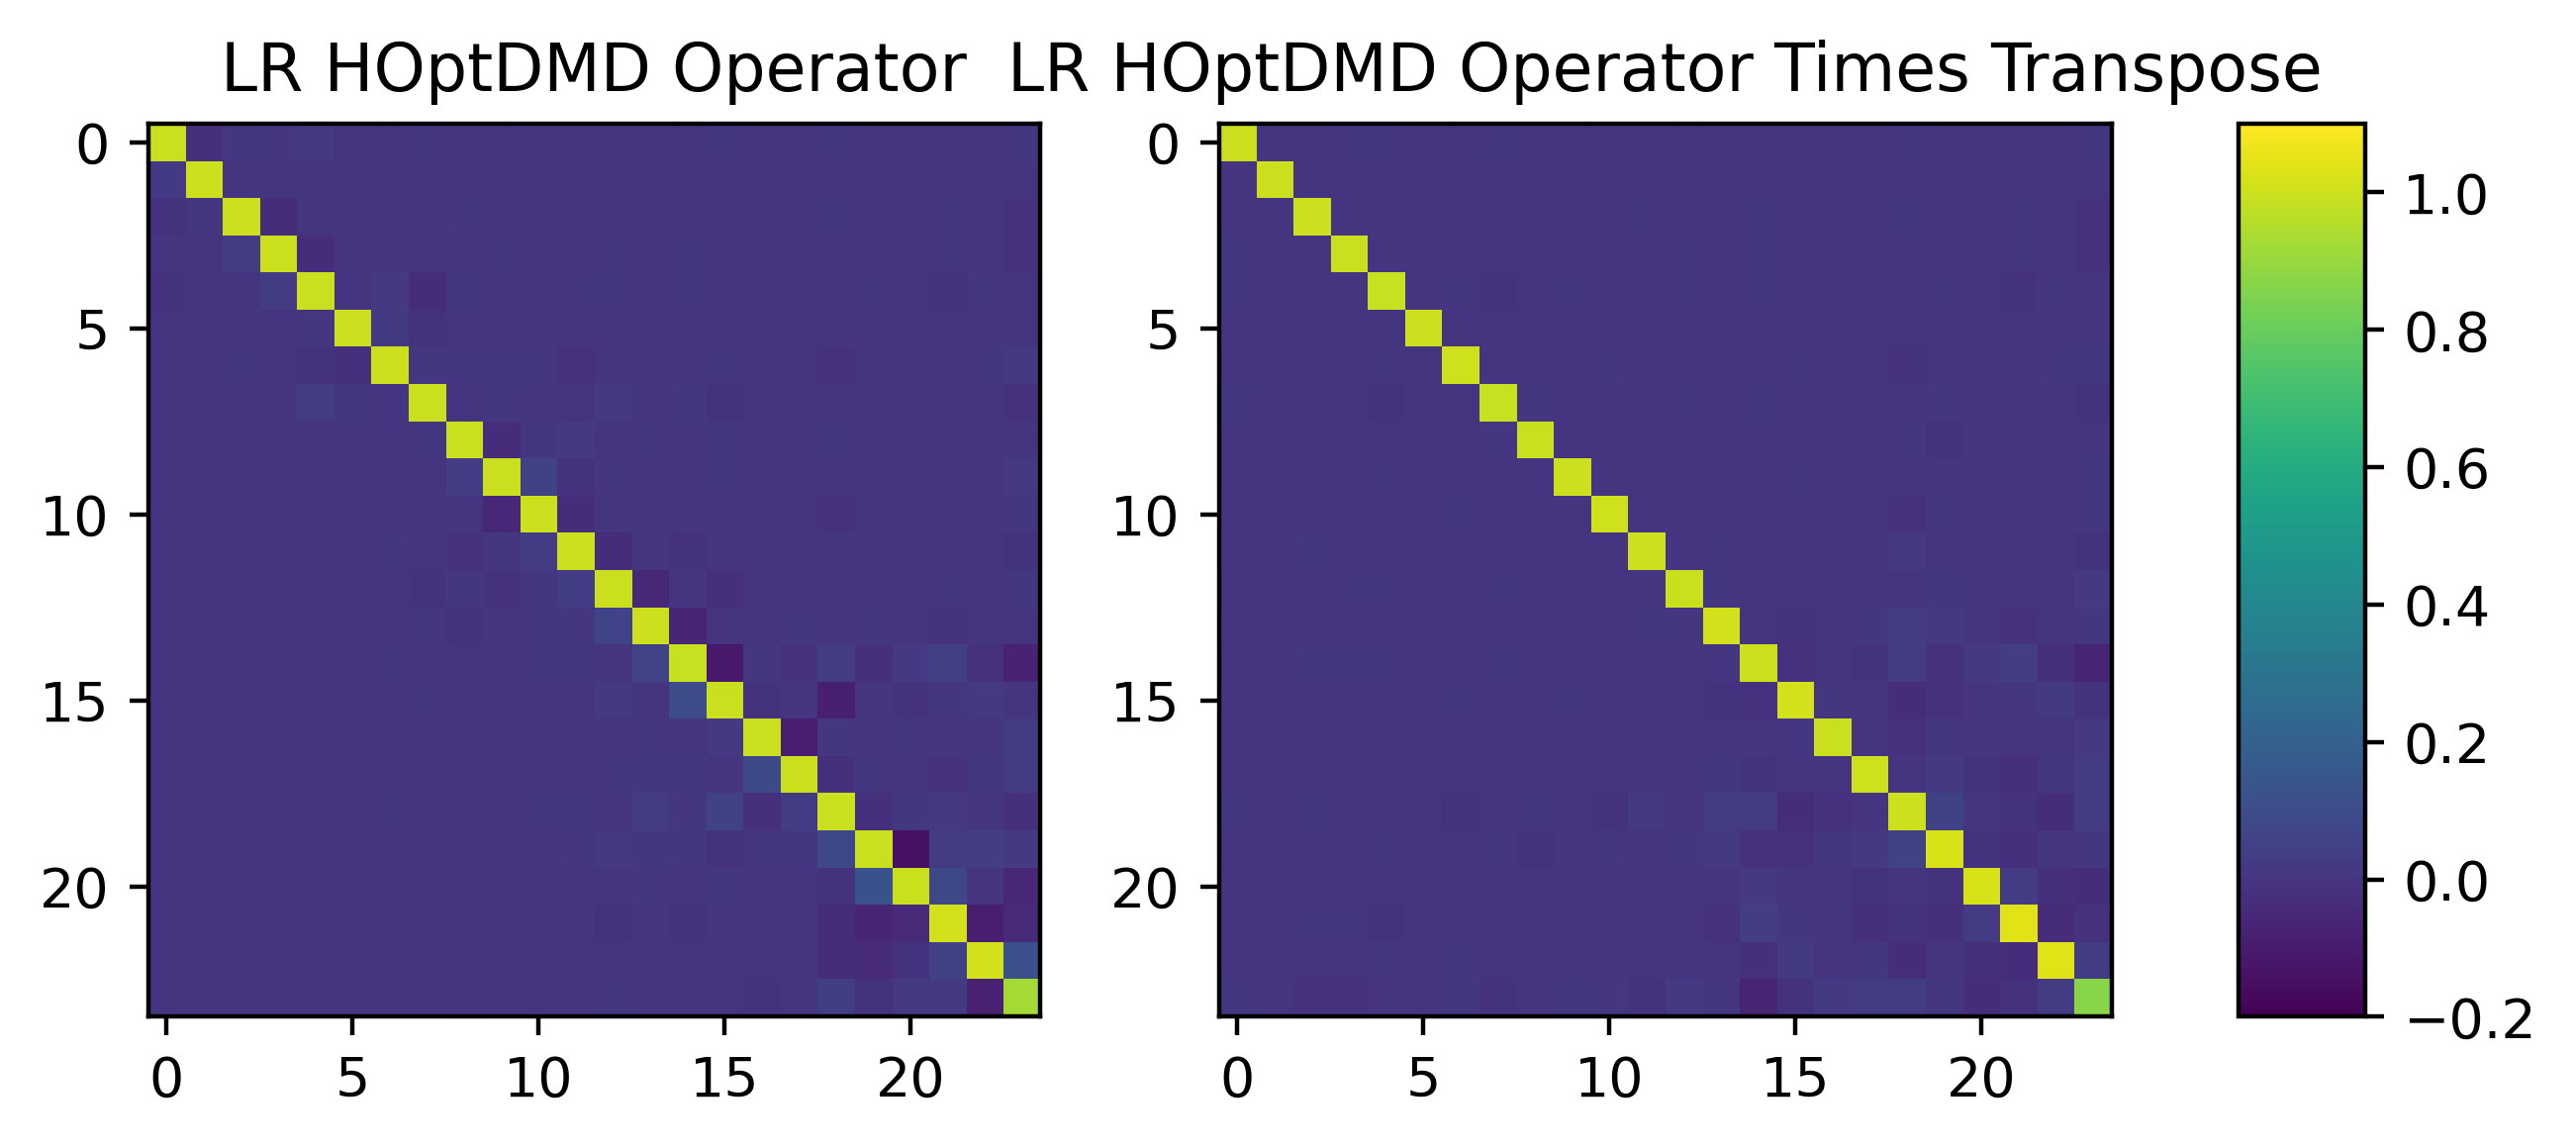

In [8]:
fig,ax = plt.subplots(1,2)
ax[0].imshow(np.real(hoptdmd_A),vmin=-0.2,vmax=1.1)
ax[0].set_title("LR HOptDMD Operator")
last_ax = ax[1].imshow(np.real(hoptdmd_A@hoptdmd_A.conjugate().T),vmin=-0.2,vmax=1.1)
ax[1].set_title("LR HOptDMD Operator Times Transpose")
cbar_ax = fig.add_axes([0.95, 0.26, 0.05, 0.47])
fig.colorbar(last_ax, cax=cbar_ax)

Interestingly, the OptDMD fit to the hankel matrix version of the data is also nearly orthogonal.

The following plot shows the diagonal trends with these four methods.

Text(0.5, 1.0, 'Magnitudes of Low Rank DMD Operator Diagonals')

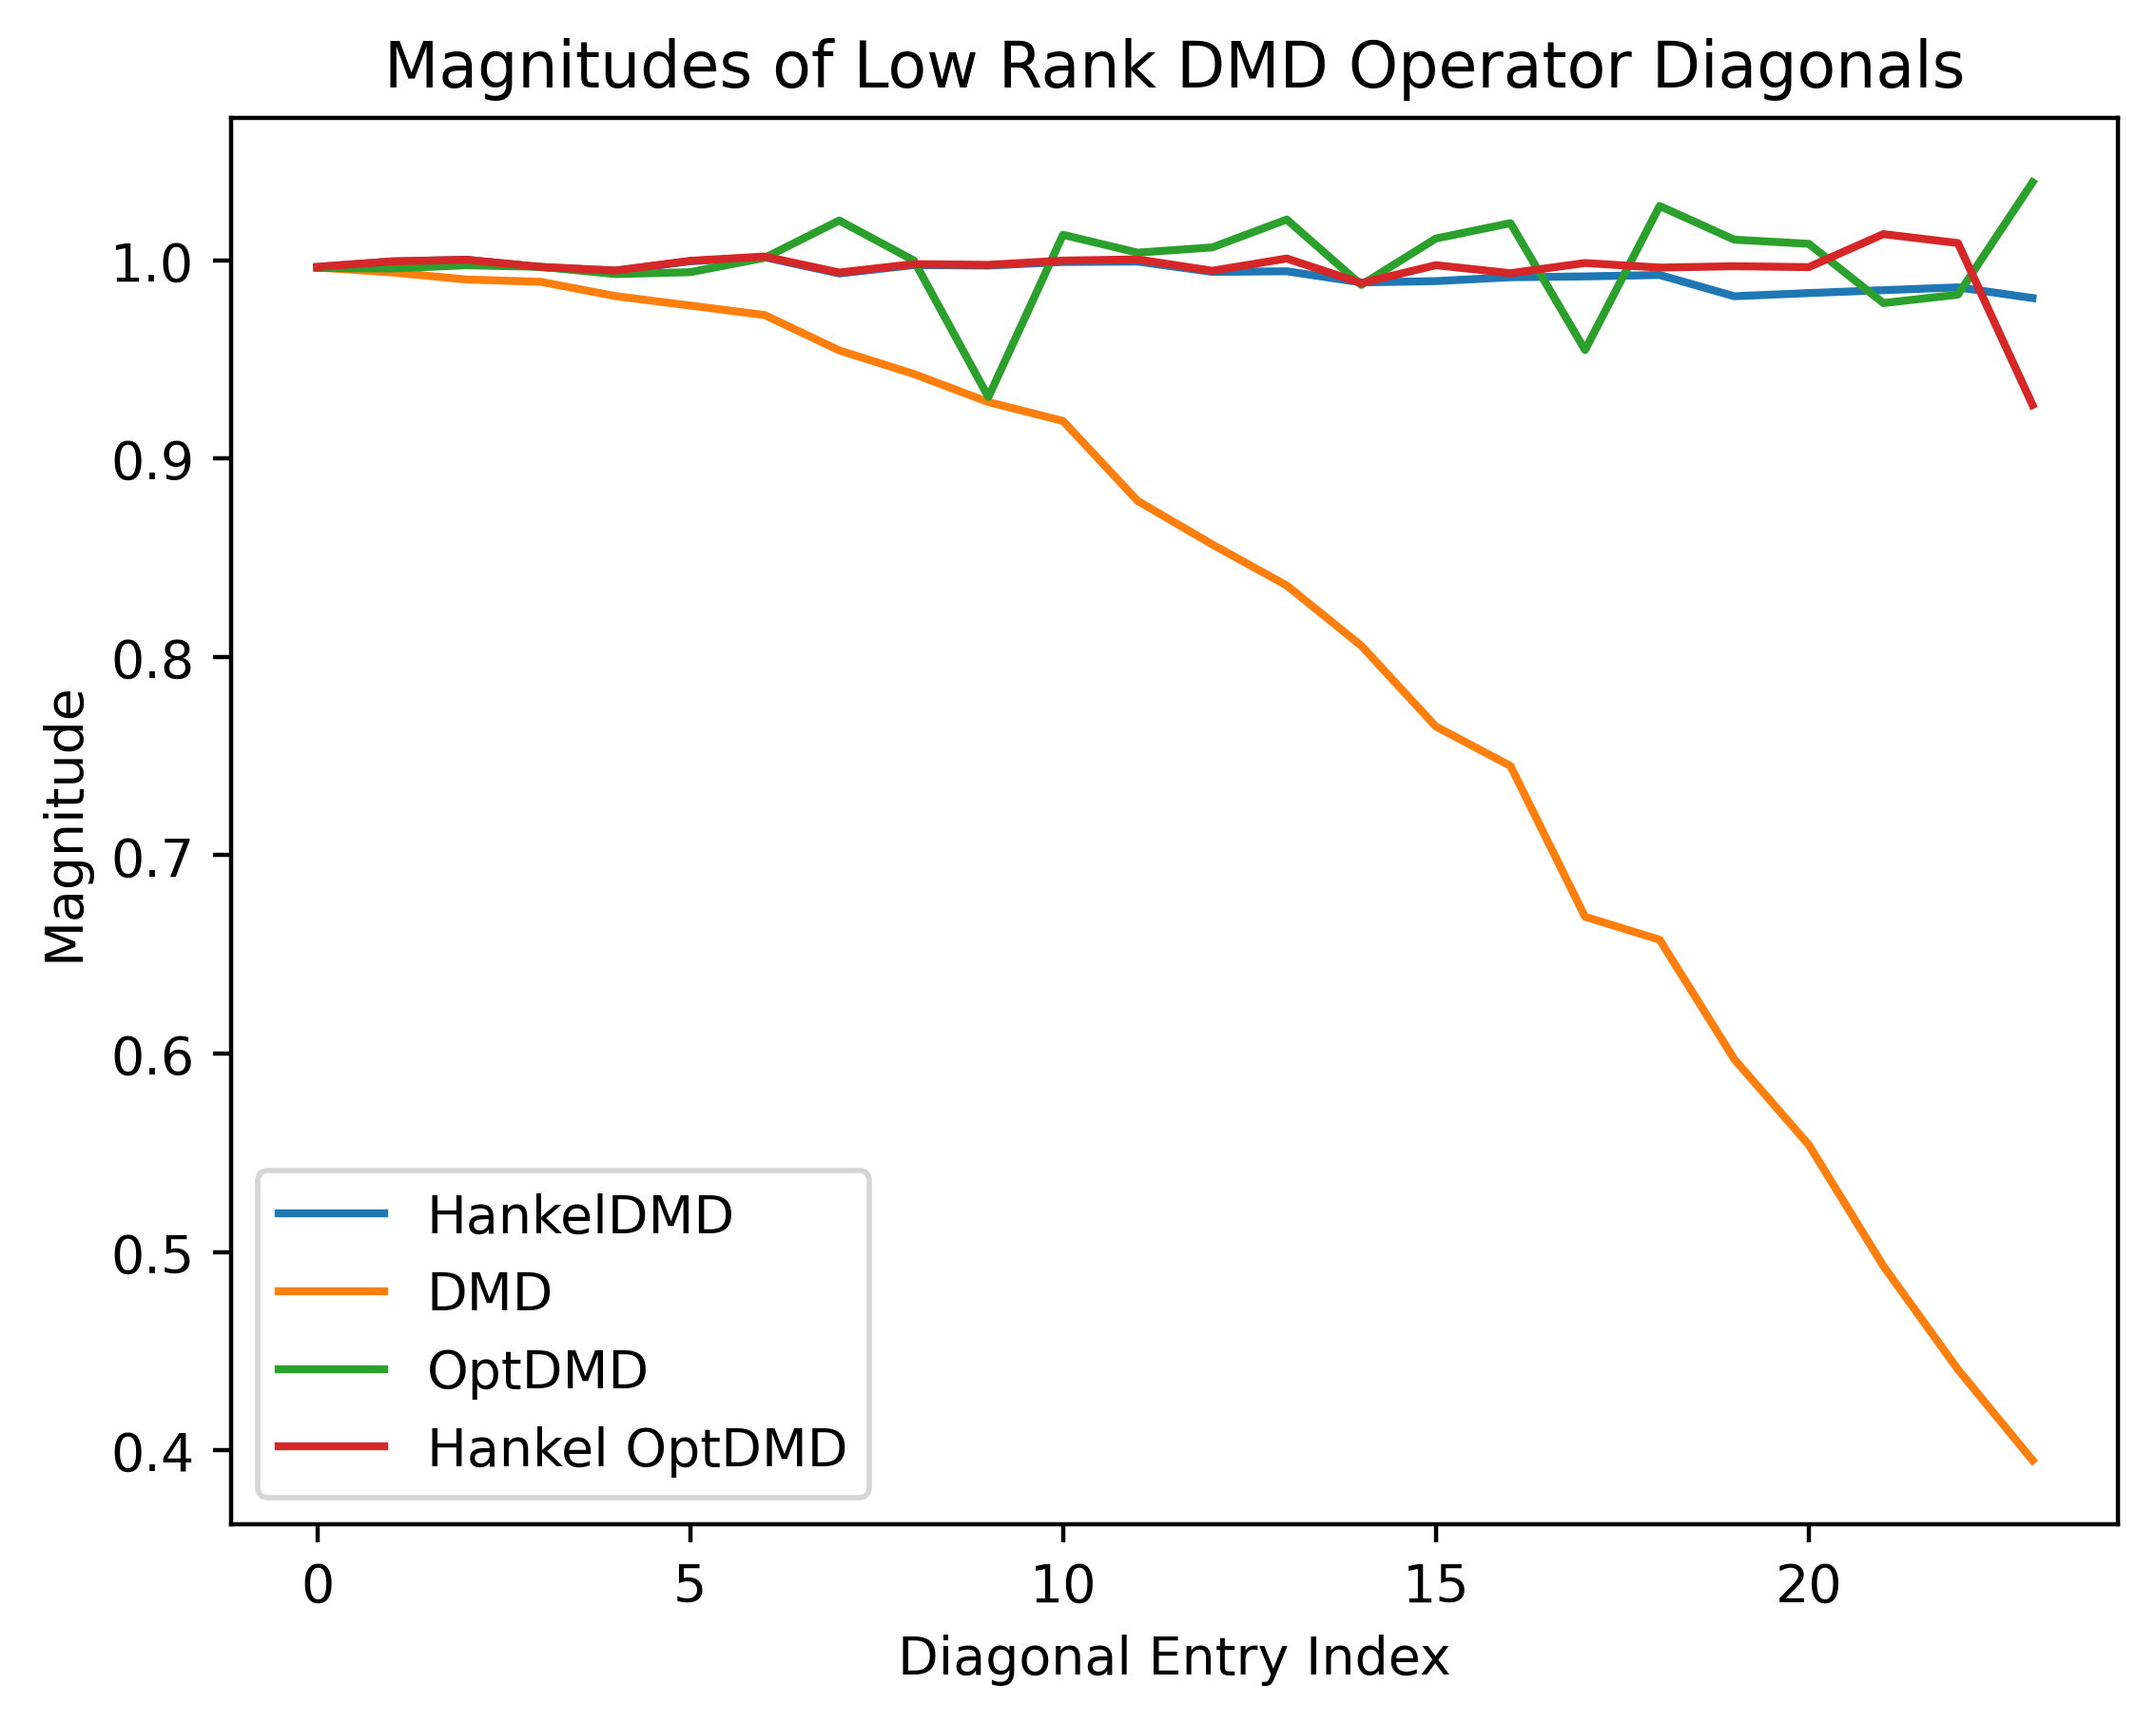

In [9]:
plt.plot(np.diag(hankel_A),label="HankelDMD")
plt.plot(np.diag(dmd_A),label="DMD")
plt.plot(np.abs(np.diag(optdmd_A)),label="OptDMD")
plt.plot(np.abs(np.diag(hoptdmd_A)),label="Hankel OptDMD")
plt.legend()
plt.xlabel("Diagonal Entry Index")
plt.ylabel("Magnitude")
plt.title("Magnitudes of Low Rank DMD Operator Diagonals")

Next let's look at how normal these operators are. By definition a matrix $A$ is normal if $A^*A=AA^*.$ So we will quantify nonnormality by computing $\|AA^*-A^*A\|_F$, i.e. the Frobenius norm of the commutator between $A^*$ and $A$.

In [10]:
hankeldmd_commutator = np.linalg.norm(hankel_A@hankel_A.T-hankel_A.T@hankel_A)
dmd_commutator = np.linalg.norm(dmd_A@dmd_A.T-dmd_A.T@dmd_A)
optdmd_commutator = np.linalg.norm(optdmd_A@optdmd_A.conjugate().T-optdmd_A.conjugate().T@optdmd_A)
hoptdmd_commutator = np.linalg.norm(hoptdmd_A@hoptdmd_A.conjugate().T-hoptdmd_A.conjugate().T@hoptdmd_A)

In [11]:
print("HankelDMD Commutator Norm: " + str(hankeldmd_commutator))
print("DMD Commutator Norm: " + str(dmd_commutator))
print("OptDMD Commutator Norm: " + str(optdmd_commutator))
print("Hankel OptDMD Commutator Norm: " + str(hoptdmd_commutator))

HankelDMD Commutator Norm: 0.006867478
DMD Commutator Norm: 0.9110981
OptDMD Commutator Norm: 126.775259604808
Hankel OptDMD Commutator Norm: 0.062376746947850524


The Hankel methods have much lower commutator norm, in agreement with the above plots showing that the Hankel methods produce nearly orthogonal low rank matrices.

This begs the question of whether or not the HankelDMD modes themselves are orthonormal, and if they are, whether or not the truncated portions needed for forecasting (the $\psi_j$s) are.

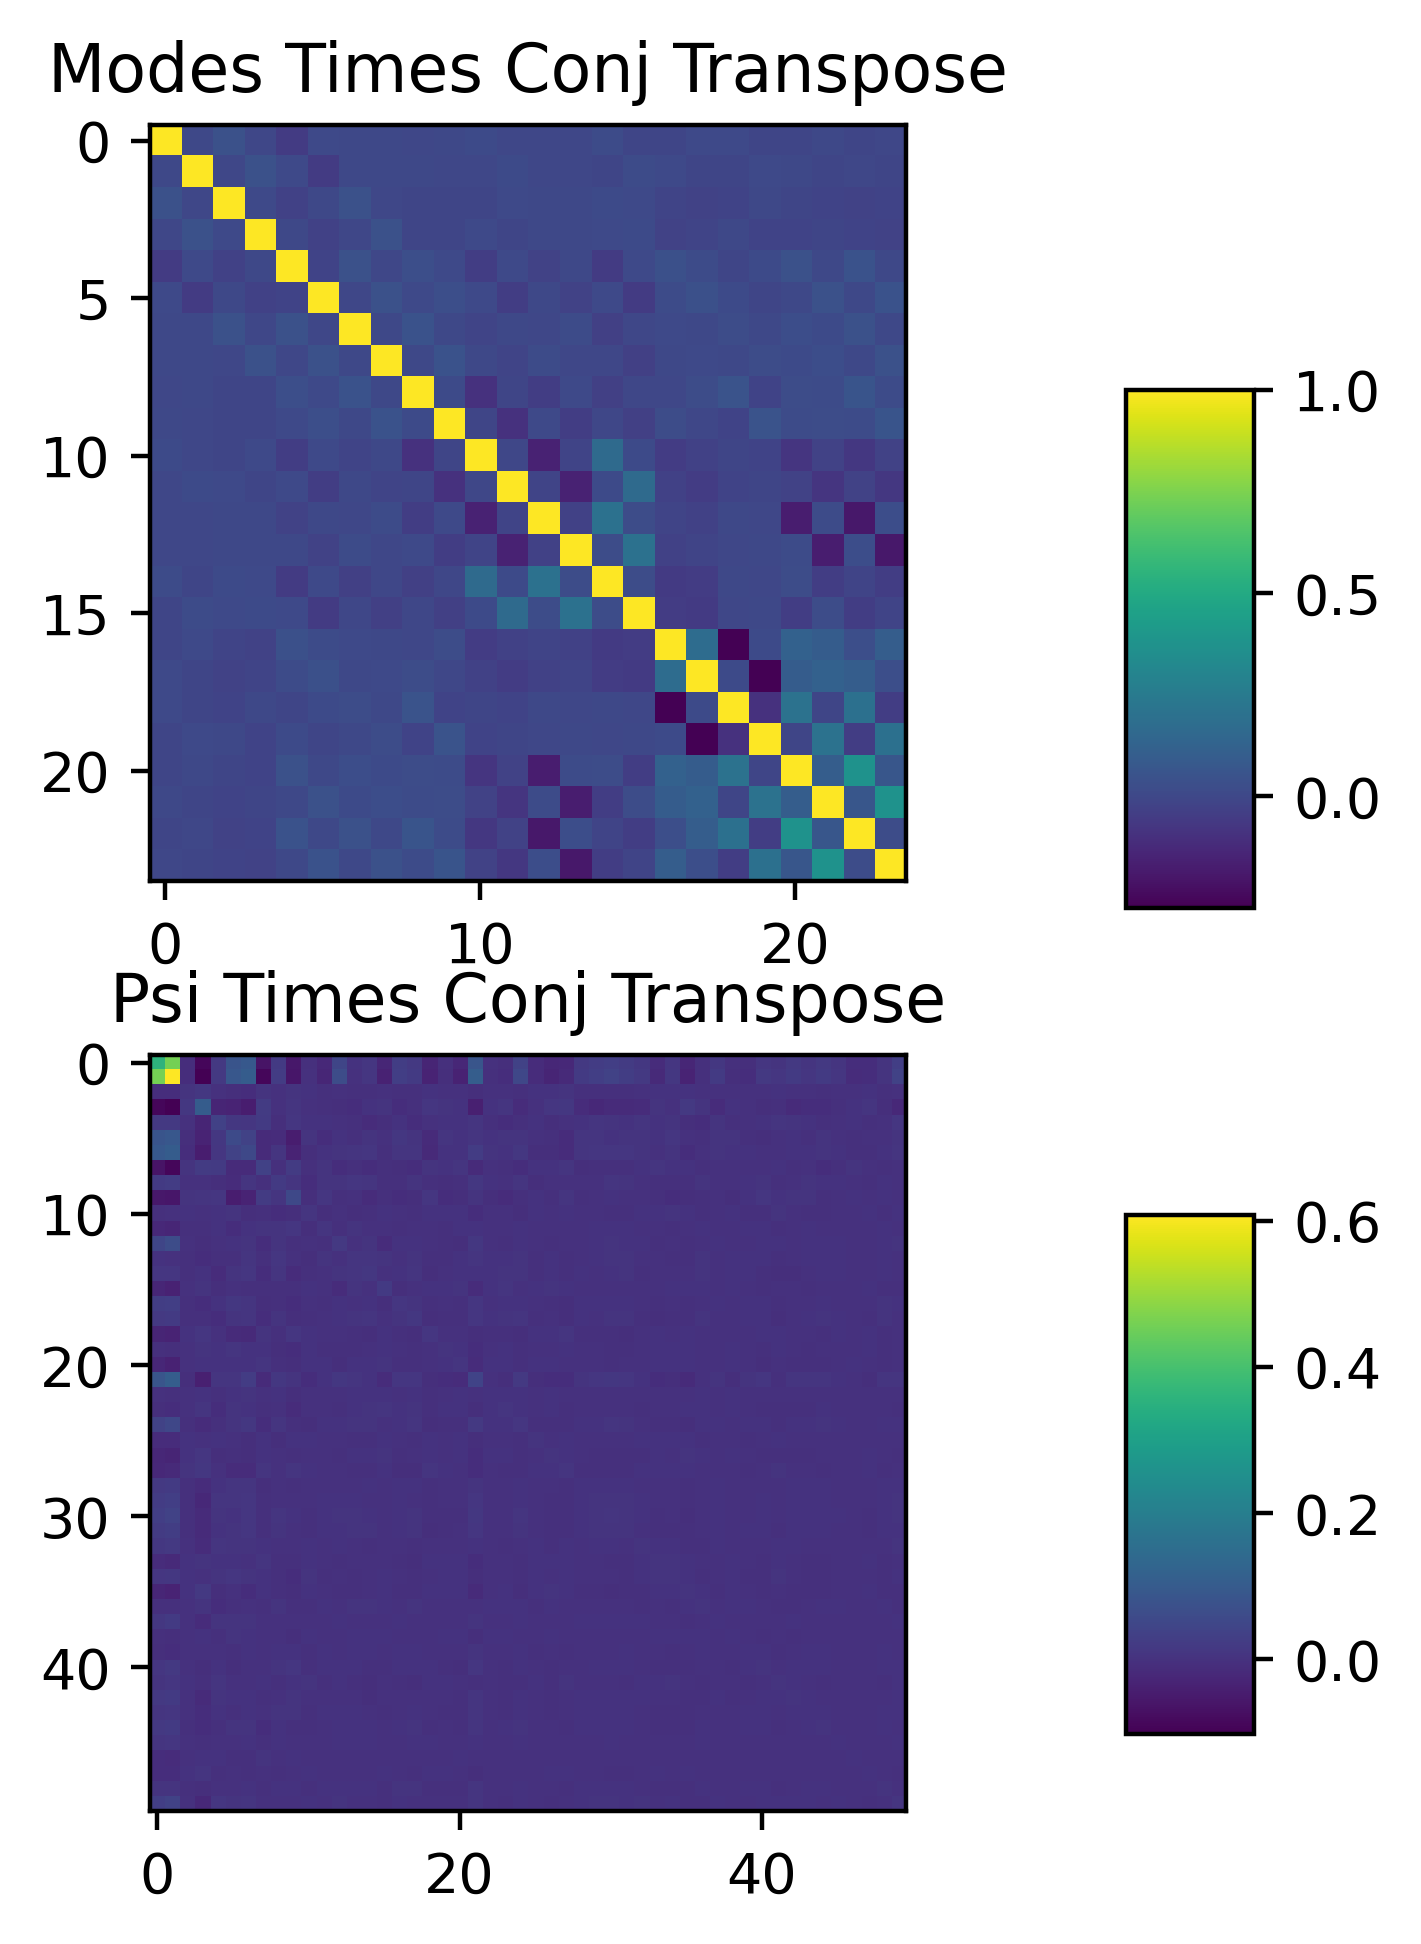

In [12]:
modes_mat = hdmd.modes.conjugate().T@hdmd.modes
fig,ax = plt.subplots(2,1)
fig.tight_layout()
first_ax = ax[0].imshow(np.real(modes_mat))
cbar_ax = fig.add_axes([0.75, 0.55, 0.05, 0.27])
ax[0].set_title("Modes Times Conj Transpose")
fig.colorbar(first_ax,cax=cbar_ax)
last_ax = ax[1].imshow(np.real(psi@psi.conjugate().T))
ax[1].set_title("Psi Times Conj Transpose")
cbar_ax_2 = fig.add_axes([0.75, 0.12, 0.05, 0.27])
fig.colorbar(last_ax, cax=cbar_ax_2)

It seems like the modes are approximately orthogonal, but the $\psi_j$s are not.

Another thing we can look at is the condition numbers of the matrices.

In [13]:
print("HankelDMD Operator Condition Number: " + str(np.linalg.cond(hankel_A)))
print("DMD Operator Condition Number: " + str(np.linalg.cond(dmd_A)))
print("OptDMD Operator Condition Number: " + str(np.linalg.cond(optdmd_A)))
print("Hankel OptDMD Operator Condition Number: " + str(np.linalg.cond(hoptdmd_A)))

HankelDMD Operator Condition Number: 1.04564
DMD Operator Condition Number: 3.5888002
OptDMD Operator Condition Number: 90.02972291521002
Hankel OptDMD Operator Condition Number: 1.1856176613982599


The OptDMD low rank operator is incredibly poorly conditioned. But in agreement with the above results, lifting to Hankel space brings the condition numbers for both methods down to one.

Let's look at the pseudospectra.

Text(0, 0.5, 'Im z')

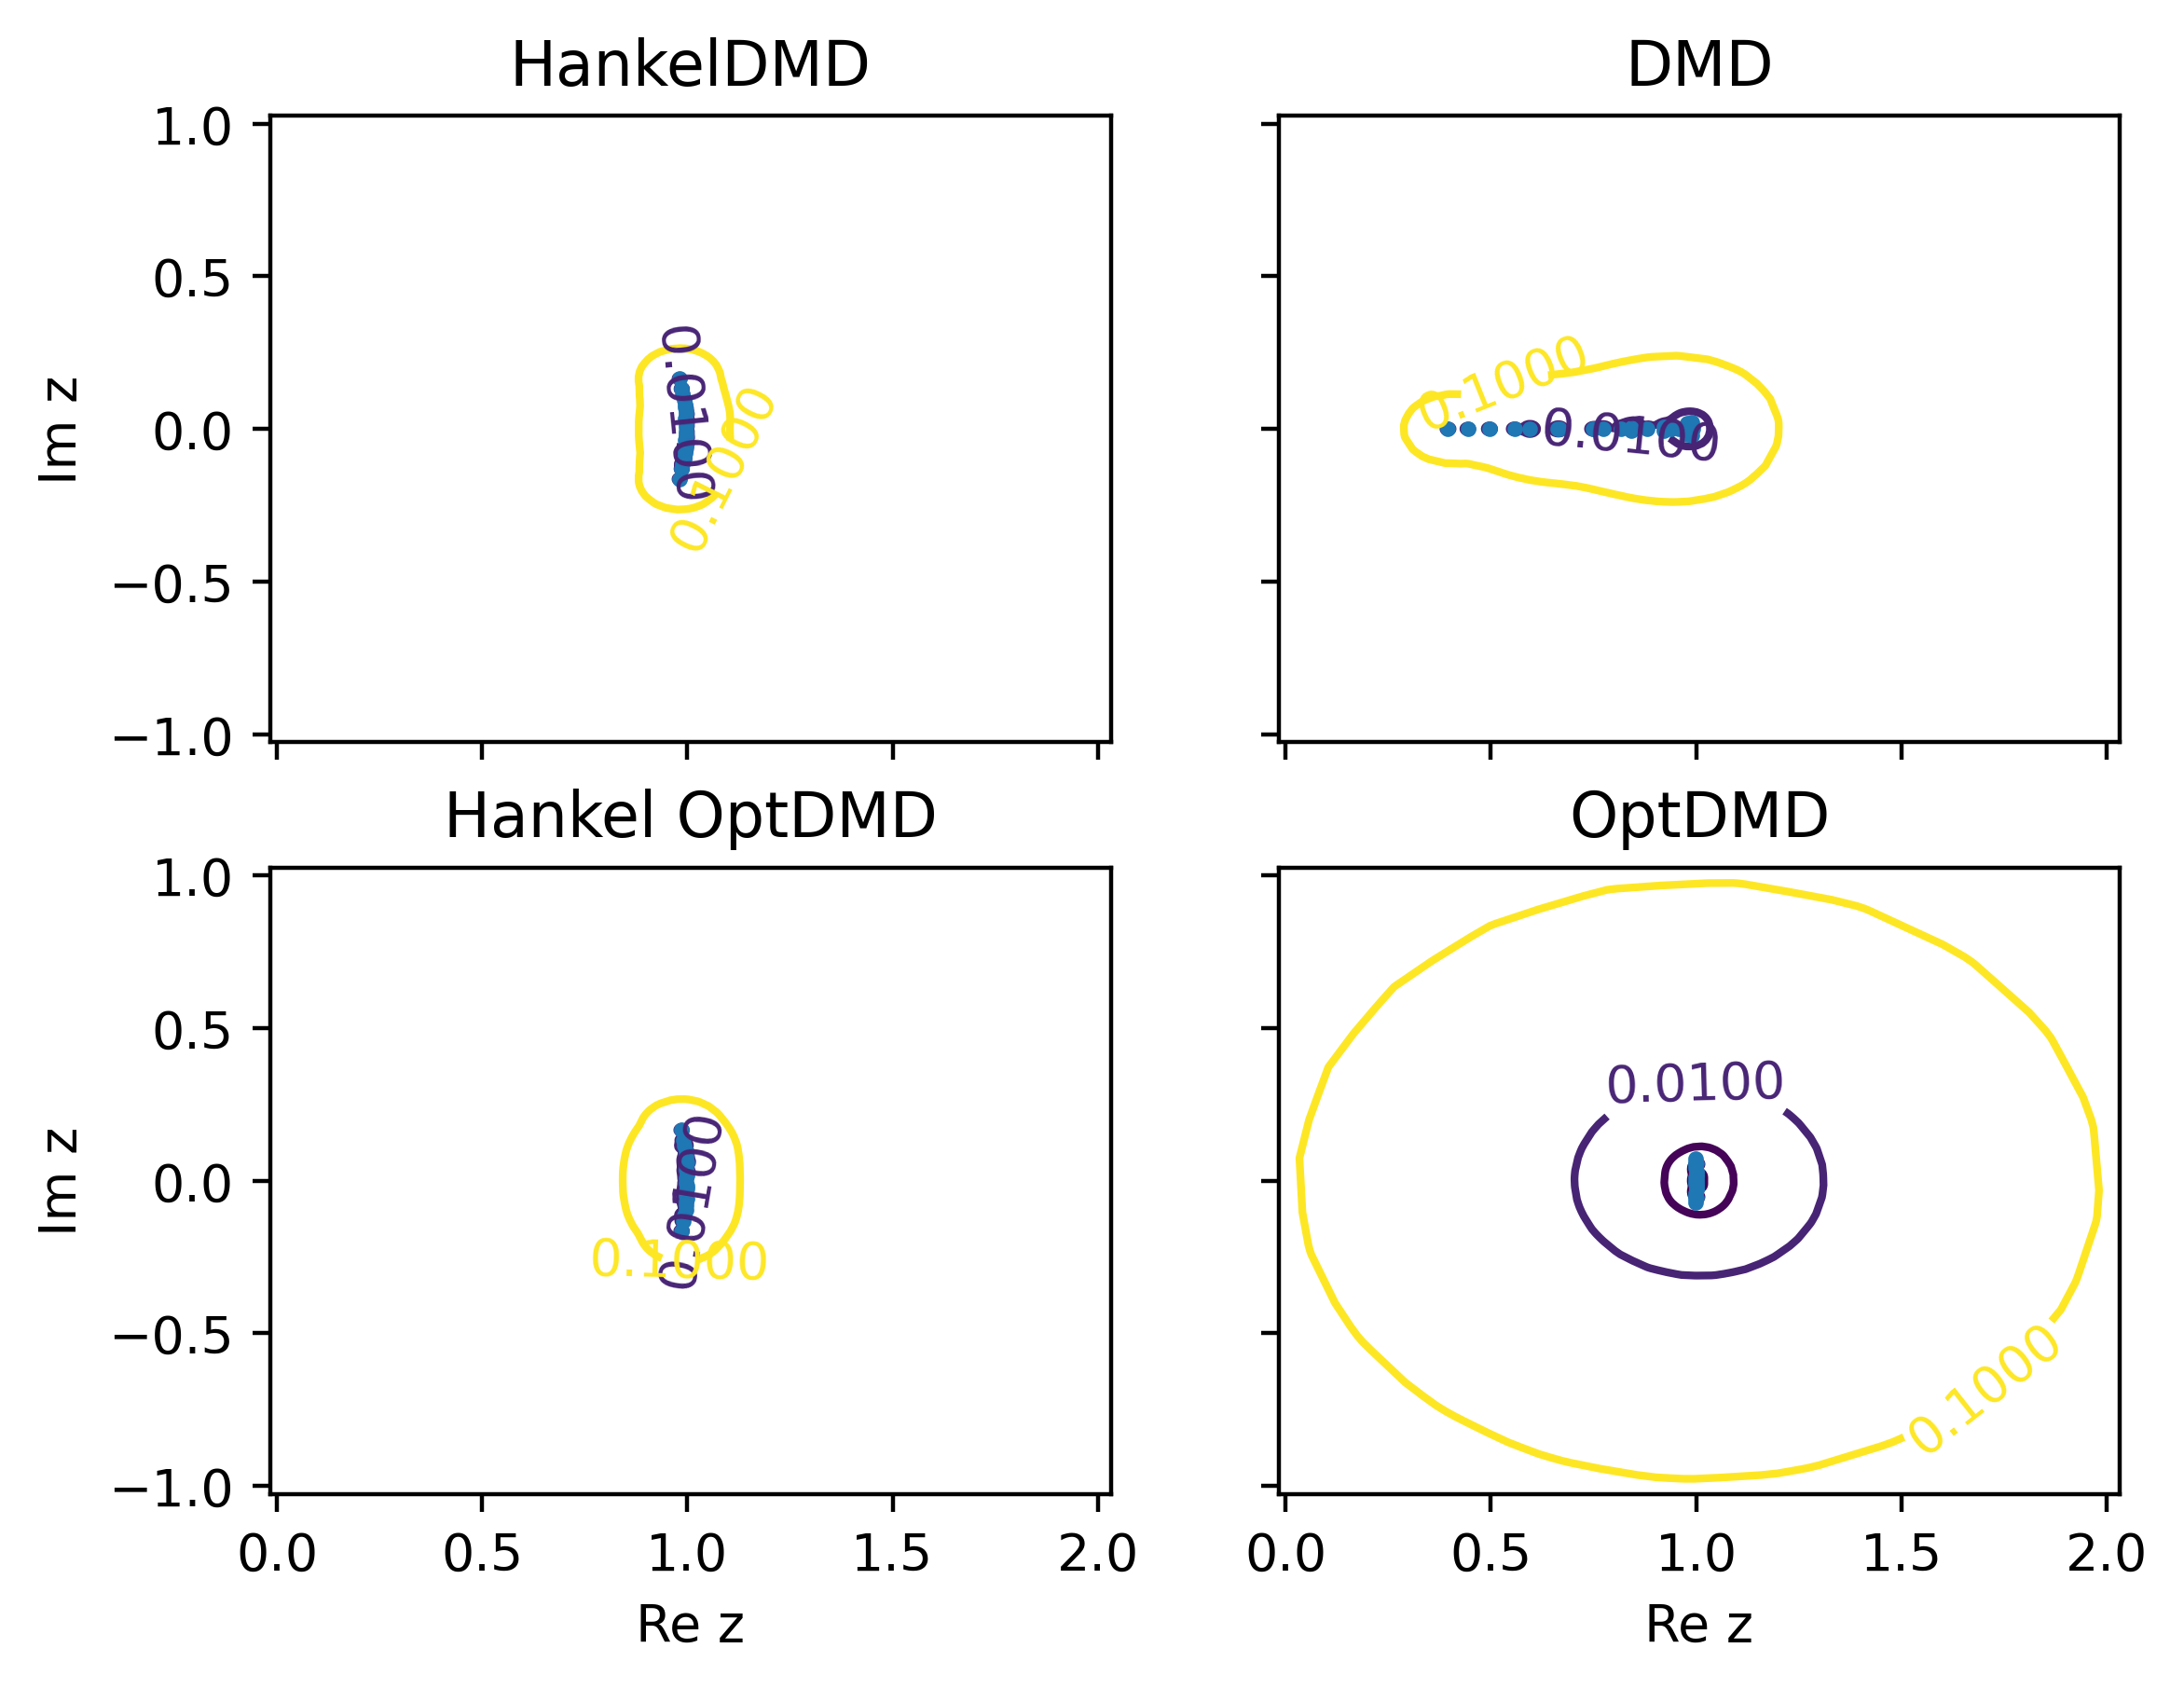

In [26]:
from pseudopy import NonnormalAuto

def plot_pseudo(pseudo,spectrum,epsilons,ax,title=None):
    """
    Plots the spectrum of a matrix as dots and its pseudospectrum
    as contours in the given ax. Modified from pseudopy to work with
    subplots.
    """
    contours = ax.tricontour(pseudo.triang, pseudo.vals, levels=epsilons)
    ax.plot(np.real(spectrum), np.imag(spectrum), 'o',markersize=2)
    vertices = []
    for collection in contours.collections:
        for path in collection.get_paths():
            vertices.append(path.vertices[:, 0] + 1j*path.vertices[:, 1])
    vertices = np.concatenate(vertices)
    eps = 0.05
    ax.set_xlim(np.min(vertices.real)-eps, np.max(vertices.real)+eps)
    ax.set_ylim(np.min(vertices.imag)-eps, np.max(vertices.imag)+eps)
    ax.clabel(contours)
    if title:
        ax.set_title(title)

fig,ax = plt.subplots(2,2,sharex=True,sharey=True)
epsilons = [10**k for k in range(-4,0)]
plot_pseudo(NonnormalAuto(hankel_A,1e-5,1),hdmd.eigs,epsilons,ax[0,0],"HankelDMD")
plot_pseudo(NonnormalAuto(dmd_A,1e-5,1),dmd.eigs,epsilons,ax[0,1],"DMD")
plot_pseudo(NonnormalAuto(hoptdmd_A,1e-5,1),np.exp(hoptdmd.eigs),epsilons,ax[1,0],"Hankel OptDMD")
plot_pseudo(NonnormalAuto(optdmd_A,1e-5,1),np.exp(optdmd.eigs),epsilons,ax[1,1],"OptDMD")
ax[1,0].set_xlabel("Re z")
ax[1,1].set_xlabel("Re z")
ax[0,0].set_ylabel("Im z")
ax[1,0].set_ylabel("Im z")

The large pseudospectrum of the OptDMD matrix together with its condition number being on the order of 1/machine epsilon explains why it is unstable even when we constrain its eigenvalues to have negative real part.

# Forecasting Statistics

Here we will attempt to compute many forecasts and determine the predictive accuracy.

In [ ]:
SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy')[:7000,:50].T
import warnings
warnings.filterwarnings('ignore')

def train_models(n: int, d: int, r: int, regularization: float = 1e-4, block_width: int = 100,
                 optdmd: bool = False) -> dict:
    """
    n: Number of time points to fit per model
    d: Amount of time delay embedding to use in each model
    r: Rank of HDMD/HOptDMD fit
    regularization: Ridge regression coefficient for HDMD
    block_width: Number of timepoints to use for computing forecasting error
    optdmd: Whether to use optdmd (True) or Hankel DMD (False)
    
    Returns: dictionary with all relevant training info.
    """
    train = {
                    'hdmds': [],
                    'optdmds': [],
                    'forecasts': [],
                    'aligned forecasts': [],
                    'shifts': [],
                    'train_SVns': [],
                    'test_SVns': [],
                    'MASEs': []
            }
    for i in tqdm(range(5000//n)):
        train_norm = np.linalg.norm(SV[:,i*n:(i+1)*n])
        train_SVn = SV[:,i*n:(i+1)*n]/train_norm
        test_SVn = SV[:,(i+1)*n:(i+1)*n+500]/train_norm
        train['train_SVns'].append(train_SVn)
        train['test_SVns'].append(test_SVn)

        hdmd = HankelDMD(r,d=d,opt=True,tikhonov_regularization=regularization)
        if optdmd:
            hankel = hdmd._pseudo_hankel_matrix(train_SVn)
            optdmd = BOPDMD(r,eig_constraints=set({'stable'}))
            optdmd.fit(hankel,np.arange(n-hdmd.d+1))
            train['optdmds'].append(optdmd)
            psi = optdmd.modes[-50:,:]*np.exp(-optdmd.eigs*(hdmd.d-1))
            forecast = psi@dynamics_hopt(optdmd,np.arange(hdmd.d,n+500),0,1)
        else:
            hdmd.fit(train_SVn)
            psi = hdmd.modes[-50:,:]*np.exp(-np.log(hdmd.eigs)*(hdmd.d-1))
            forecast = psi@dynamics(hdmd,np.arange(hdmd.d,n+500),0,1)
        train['hdmds'].append(hdmd)
        train['forecasts'].append(forecast)

        errors = []
        for i in range(-100,100):
            errors.append(MASE(forecast[:,n-hdmd.d+i:n-hdmd.d+200+i],test_SVn[:,:200],train_SVn))
        shift = np.argmin(errors)-100
        aligned_forecast = forecast[:,n-hdmd.d+shift:]
        train['shifts'].append(shift)
        train['aligned forecasts'].append(aligned_forecast)

        MASEs = []
        for block in range(0,8*block_width,block_width):
            MASEs.append(MASE(aligned_forecast[:,block:block+block_width],test_SVn[:,block:block+block_width],train_SVn))
        train['MASEs'].append(MASEs)
    return train

In [ ]:
train_500 = train_models(500,250,24,1e-4,50,False)

In [ ]:
train_1000 = train_models(1000,500,35,1e-4,50,False)

In [ ]:
train_1000_optdmd = train_models(1000,500,35,1e-4,50,True)

In [ ]:
random_model = {
                'forecasts': [],
                'aligned forecasts': [],
                'shifts': [],
                'train_SVns': [],
                'test_SVns': [],
                'MASEs': []
            }
for i in tqdm(range(10)):
    train_norm = np.linalg.norm(SV[:,i*500:(i+1)*500])
    train_SVn = SV[:,i*500:(i+1)*500]/train_norm
    test_SVn = SV[:,(i+1)*500:(i+2)*500]/train_norm
    random_model['train_SVns'].append(train_SVn)
    random_model['test_SVns'].append(test_SVn)
    
    forecast = np.random.normal(np.mean(train_SVn),np.std(train_SVn),(50,750))
    random_model['forecasts'].append(forecast)
    
    errors = []
    for i in range(-100,100):
        errors.append(MASE(forecast[:,250+i:450+i],test_SVn[:,:200],train_SVn))
    shift = np.argmin(errors)-100
    aligned_forecast = forecast[:,250+shift:]
    random_model['shifts'].append(shift)
    random_model['aligned forecasts'].append(aligned_forecast)
    
    MASEs = []
    for block in range(0,400,50):
        MASEs.append(MASE(aligned_forecast[:,block:block+50],test_SVn[:,block:block+50],train_SVn))
    random_model['MASEs'].append(MASEs)

In [ ]:
MASE_hankel_500 = np.mean(np.array(train_500['MASEs']),axis=0)
MASE_hankel_500_sem = np.std(np.array(train_500['MASEs']),axis=0)
MASE_hankel_1000 = np.mean(np.array(train_1000['MASEs']),axis=0)
MASE_hankel_1000_sem = np.std(np.array(train_1000['MASEs']),axis=0)
MASE_random = np.mean(np.array(random_model['MASEs']),axis=0)
MASE_random_sem = np.std(np.array(random_model['MASEs']),axis=0)

In [ ]:
plt.plot(np.arange(50,450,50),MASE_hankel_500,label="HankelDMD 500")
plt.fill_between(np.arange(50,450,50),MASE_hankel_500-MASE_hankel_500_sem,MASE_hankel_500+MASE_hankel_500_sem,alpha=0.5)
plt.plot(np.arange(50,450,50),MASE_hankel_1000,label="HankelDMD 1000")
plt.fill_between(np.arange(50,450,50),MASE_hankel_1000-MASE_hankel_1000_sem,MASE_hankel_1000+MASE_hankel_1000_sem,alpha=0.5)
plt.plot(np.arange(50,450,50),MASE_random,label="White Noise Model")
plt.fill_between(np.arange(50,450,50),MASE_random-MASE_random_sem,MASE_random+MASE_random_sem,alpha=0.5)
plt.xlabel("Forecast Time")
plt.ylabel("MASE")
plt.title("HankelDMD Forecast MASEs (500 Timepoint Fit)")
plt.legend()